# Appendix C | Polynomial Regression Model

---

# Imports

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures, PowerTransformer, StandardScaler

from utils.read_csv_to_df import read_csv_to_df

# Defaults

In [2]:
SEED = 42
np.random.seed(SEED)

plt.rcParams['figure.figsize'] = (6.4, 4.8)
TARGET = 'Life Ladder'

# Fetch Data

Only the training set is used here, same as Appendix B. The test set is held back so it plays no part in choosing the model.

In [3]:
train_path = '/Q1_OLD/DATA/happiness_data_train.csv'
train_df = read_csv_to_df(path=train_path)

X = train_df.drop(columns=TARGET)
y = train_df[TARGET]

print(f'X: {X.shape[0]} rows x {X.shape[1]} features, y: {TARGET}')

X: 1559 rows x 8 features, y: Life Ladder


# Preprocessing

Same first step as Appendix B (median impute, Yeo-Johnson on the four skewed features, standardize the rest), followed by two new steps:
- **`PolynomialFeatures(degree)`** adds every power and every product of features up to `degree`. With degree 2 that means each squared feature (ex: GDP²) plus every pair multiplied together (ex: GDP x Social support). The products let the model learn **interactions**: the effect of one feature can depend on the level of another.
- **`StandardScaler` again**, because the new columns are not on the same scale as the originals (a cubed z-score can reach the hundreds). SGD takes the same step size for every weight, so it needs every column on a comparable scale or it diverges.

As before, everything sits in one `Pipeline`, so every step is refit on each training fold only.

In [4]:
SKEWED_FEATURES = ['Perceptions of corruption', 'Social support', 'Generosity', 'Negative affect']
OTHER_FEATURES = [f for f in X.columns if f not in SKEWED_FEATURES]


def make_preprocessor():
	"""Build the imputing / transforming / scaling step from Appendix B."""
	return ColumnTransformer([
		('skewed', make_pipeline(SimpleImputer(strategy='median'), PowerTransformer(method='yeo-johnson')), SKEWED_FEATURES),
		('other', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), OTHER_FEATURES),
	], verbose_feature_names_out=False)


# short, space free names so polynomial terms read clearly (ex: 'GDP x Social^2')
SHORT_NAMES = {
	'Log GDP per capita': 'GDP',
	'Social support': 'Social',
	'Healthy life expectancy at birth': 'LifeExp',
	'Freedom to make life choices': 'Freedom',
	'Generosity': 'Generosity',
	'Perceptions of corruption': 'Corruption',
	'Positive affect': 'PosAffect',
	'Negative affect': 'NegAffect',
}


def poly_term_names(fitted_pipeline):
	"""Return readable names for the polynomial terms of a fitted pipeline."""
	inputs = [SHORT_NAMES[f] for f in fitted_pipeline['pre'].get_feature_names_out()]
	return [name.replace(' ', ' x ') for name in fitted_pipeline['poly'].get_feature_names_out(inputs)]


def make_pipeline_for(regressor, degree):
	"""Preprocess, expand to polynomial features of the given degree, rescale, then fit the regressor."""
	return Pipeline([
		('pre', make_preprocessor()),
		('poly', PolynomialFeatures(degree=degree, include_bias=False)),
		('scale', StandardScaler()),
		('model', regressor),
	])

The number of columns grows fast with the degree, while the number of rows stays fixed (about 1,170 per training fold):

In [5]:
DEGREES = [1, 2, 3, 4, 5]

n_poly_features = {d: PolynomialFeatures(degree=d, include_bias=False).fit(np.zeros((1, X.shape[1]))).n_output_features_ for d in DEGREES}
pd.DataFrame({
	'features': n_poly_features,
	'training rows per fold': len(X) * 3 // 4,
}).rename_axis('degree').T

degree,1,2,3,4,5
features,8,44,164,494,1286
training rows per fold,1169,1169,1169,1169,1169


# Cross-Validation & Evaluation Metric

Identical to Appendix B so the results are directly comparable: **4-fold cross-validation** shuffled with the same seed (so the folds are the exact same rows), **RMSE** as the main metric, with R² and MAE alongside.

The **train RMSE vs validation RMSE gap** is the main tool for QE's over/underfitting question:
- **Underfitting (high bias):** train and validation RMSE are both high and close together. The model is too simple to capture the pattern.
- **Overfitting (high variance):** train RMSE is low but validation RMSE is much higher. The model has memorized noise in the training folds that does not carry over to new rows.
- **Good fit:** validation RMSE is as low as it gets, with a modest gap.

In [6]:
cv = KFold(n_splits=4, shuffle=True, random_state=SEED)
scoring = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'}
DIVERGED = 10  # any RMSE above this (the target only spans 0 to 10) means training blew up

results = []  # one row per model, filled by evaluate()
models = {}  # name -> unfitted pipeline, so the selected model can be rebuilt later


def evaluate(name, regressor, degree, **params):
	"""Cross-validate the polynomial pipeline on the training set and record the scores.

	Extra keyword arguments are stored in the results table as hyperparameter columns.
	"""
	pipeline = make_pipeline_for(regressor, degree)
	config = (degree, type(regressor).__name__, tuple(sorted(regressor.get_params().items())))
	scored = next((r for r in results if r['config'] == config), None)  # same settings already ran under another name

	if scored is None:
		with warnings.catch_warnings():
			warnings.simplefilter('ignore')  # ConvergenceWarning / overflow from runs that diverge
			scores = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, return_train_score=True)
		scored = {
			'train RMSE': -scores['train_rmse'].mean(),
			'val RMSE': -scores['test_rmse'].mean(),
			'val RMSE std': scores['test_rmse'].std(),
			'gap': -scores['test_rmse'].mean() + scores['train_rmse'].mean(),
			'val MAE': -scores['test_mae'].mean(),
			'val R2': scores['test_r2'].mean(),
		}

	score_columns = ['train RMSE', 'val RMSE', 'val RMSE std', 'gap', 'val MAE', 'val R2']
	row = {'model': name, 'degree': degree, **params, **{c: scored[c] for c in score_columns}, 'config': config}
	results.append(row)
	models[name] = pipeline
	return row


def results_table(names):
	"""Return the results rows for the given model names as a rounded DataFrame, in the given order."""
	table = pd.DataFrame([r for r in results if r['model'] in names]).set_index('model').loc[list(names)]
	return table.drop(columns='config').dropna(axis=1, how='all').round(4)


def show_diverged(table, columns=('train RMSE', 'val RMSE', 'val RMSE std', 'gap', 'val MAE', 'val R2')):
	"""Replace the scores of SGD runs that blew up with the word 'diverged' so the table stays readable."""
	table = table.drop(columns='config', errors='ignore').round(4).astype({c: object for c in columns if c in table})
	blown_up = table['val RMSE'].astype(float) > DIVERGED
	if 'method' in table:
		blown_up &= table['method'] != 'closed form'  # closed form has no learning rate: its numbers are real, just bad
	for c in columns:
		if c in table:
			table.loc[blown_up, c] = 'diverged'
	return table

# QE.1 Closed Form vs SGD Across Polynomial Degrees

Repeats QD.1 and QD.2 (closed form and SGD, no penalty) for every degree from 1 to 5. Degree 1 is the linear model from Appendix B.
- **Normal Equation**, $\hat{\theta} = (X^T X)^{-1} X^T y$, implemented by hand as in Appendix B.
- **`LinearRegression`**, which solves the same problem with the **SVD** (`scipy.linalg.lstsq`).
- **`SGDRegressor`** with default settings and `penalty=None`.

In [7]:
class NormalEquationRegressor(RegressorMixin, BaseEstimator):
	"""Ordinary least squares solved with the Normal Equation."""

	def fit(self, X, y):
		X_b = np.c_[np.ones(len(X)), X]  # add the intercept column
		theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ np.asarray(y)
		self.intercept_, self.coef_ = theta[0], theta[1:]
		return self

	def predict(self, X):
		return self.intercept_ + np.asarray(X) @ self.coef_

In [8]:
degree_names = {'Normal Equation': [], 'LinearRegression (SVD)': [], 'SGD (no penalty)': []}
for degree in DEGREES:
	for label, regressor, method in [
		('Normal Equation', NormalEquationRegressor(), 'closed form'),
		('LinearRegression (SVD)', LinearRegression(), 'closed form'),
		('SGD (no penalty)', SGDRegressor(penalty=None, random_state=SEED), 'SGD'),
	]:
		name = f'{label}, degree {degree}'
		evaluate(name, regressor, degree, method=method)
		degree_names[label].append(name)

show_diverged(pd.DataFrame([r for r in results if r['model'] in sum(degree_names.values(), [])]).set_index('model').sort_values('degree', kind='stable'))

,degree,method,train RMSE,val RMSE,val RMSE std,gap,val MAE,val R2
model,,,,,,,,
"Normal Equation, degree 1",1,closed form,0.5316,0.5343,0.0307,0.0027,0.4151,0.7675
"LinearRegression (SVD), degree 1",1,closed form,0.5316,0.5343,0.0307,0.0027,0.4151,0.7675
"SGD (no penalty), degree 1",1,SGD,0.5318,0.5342,0.0307,0.0025,0.4153,0.7675
"Normal Equation, degree 2",2,closed form,0.4929,0.5143,0.0248,0.0214,0.3992,0.7847
"LinearRegression (SVD), degree 2",2,closed form,0.4929,0.5143,0.0248,0.0214,0.3992,0.7847
"SGD (no penalty), degree 2",2,SGD,0.4953,0.5121,0.0246,0.0169,0.3978,0.7865
"Normal Equation, degree 3",3,closed form,0.4254,0.5151,0.0324,0.0897,0.3894,0.7834
"LinearRegression (SVD), degree 3",3,closed form,0.4254,0.5151,0.0324,0.0897,0.3894,0.7834
"SGD (no penalty), degree 3",3,SGD,0.448,0.5039,0.0299,0.0559,0.387,0.793


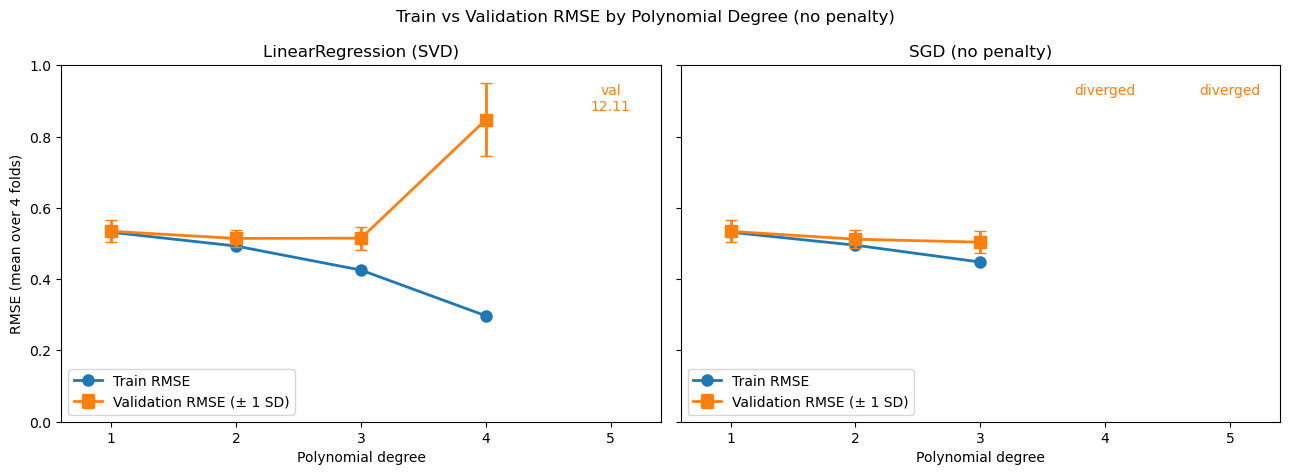

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, label in zip(axes, ['LinearRegression (SVD)', 'SGD (no penalty)']):
	table = results_table(degree_names[label])
	ok = table[table['val RMSE'] <= 0.95]
	ax.plot(ok['degree'], ok['train RMSE'], marker='o', markersize=8, lw=2, label='Train RMSE')
	ax.errorbar(ok['degree'], ok['val RMSE'], yerr=ok['val RMSE std'], marker='s', markersize=8, lw=2, capsize=4, label='Validation RMSE (± 1 SD)')
	for degree, val in zip(table['degree'], table['val RMSE']):
		if val > 0.95:  # off the chart: label where it went instead
			text = 'diverged' if (val > DIVERGED and label.startswith('SGD')) else f'val\n{val:.2f}'
			ax.annotate(text, xy=(degree, 0.95), ha='center', va='top', color='tab:orange')
	ax.set_xticks(DEGREES)
	ax.set_xlim(0.6, 5.4)
	ax.set_xlabel('Polynomial degree')
	ax.set_title(label)
	ax.legend(loc='lower left')
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('RMSE (mean over 4 folds)')
fig.suptitle('Train vs Validation RMSE by Polynomial Degree (no penalty)')
plt.tight_layout()
plt.show()

In [10]:
sgd_degree_table = results_table(degree_names['SGD (no penalty)'])
POLY_DEGREE = int(sgd_degree_table.loc[sgd_degree_table['val RMSE'].idxmin(), 'degree'])
print(f'Lowest validation RMSE for unpenalized SGD: degree {POLY_DEGREE} ({sgd_degree_table["val RMSE"].min():.4f})')

Lowest validation RMSE for unpenalized SGD: degree 3 (0.5039)


#### Notes / Observations

**Closed form vs SGD**
- **The Normal Equation and SVD agree exactly up to degree 4**, same as in Appendix B.
- **At degree 5 they split apart.** There are 1,286 features but only 1,169 rows per training fold, so $X^T X$ is singular (it has no inverse). The hand-written Normal Equation still calls `inv`, gets numerical garbage, and lands at validation RMSE 5,459. The SVD handles this case by picking the smallest set of weights that fits, and fits every training row *exactly* (train RMSE 0.0), which is still useless on new rows (validation RMSE 12.1, worse than predicting the mean). **This is why SVD is the safer closed-form method.**
- **SGD diverges from degree 4 up.** Each SGD update moves the weights by roughly `eta0 x (size of the row)²`. Even after rescaling, the most extreme row's squared size grows from 37 at degree 1 to 5,440 at degree 3 and about 30,000 at degree 4. With the default `eta0 = 0.01` a single update on such a row overshoots, the next overshoots further, and the weights blow up. QE.3 shows degree 4 *can* train with a 100x smaller learning rate.

**Over/underfitting by degree** (train vs validation RMSE)
- **Degree 1 (linear) underfits:** train and validation are both high and nearly equal (0.532 vs 0.534), as Appendix B found.
- **Degree 2 helps a little:** validation drops to 0.514 (closed form) / 0.512 (SGD), R² rises from 0.77 to 0.79. The gap grows to about 0.02, still small.
- **Degree 3 starts overfitting:** for the closed form, train RMSE falls another 0.07 (to 0.425) but validation does not improve at all (0.515 vs 0.514), so the gap jumps to 0.090. The extra flexibility is being spent on noise.
- **Degree 4 overfits badly:** train RMSE 0.297, validation 0.848 ± 0.103 (R² 0.41). It fits the training folds much better than any other model and new rows much worse.
- **SGD at degree 3 beats the closed form at degree 3** (0.504 vs 0.515) with a smaller gap (0.056 vs 0.090). SGD stops after a few epochs, before it has fully fit the noise. Stopping early works like a mild penalty on its own, so SGD ends up with smaller weights than the exact solution.
- **Degree 3 is carried forward.** It has the lowest unpenalized SGD validation RMSE, and its train / validation gap is large enough that a penalty has something to fix.

# QE.2 Regularization with SGD: Ridge, Lasso and Elastic Net

Repeats QD.3 at the degree chosen above. This is where regularization should finally matter: QE.1 showed a much larger train / validation gap than the linear model had, and shrinking the weights is the standard fix for that.

Same three penalties as Appendix B (`l1_ratio = 0.5` for Elastic Net). The penalty values are shifted down one step to **0.001, 0.01 and 0.1**, since Appendix B showed that `alpha = 1.0` wipes out most of the model, and there are now many more weights sharing the penalty.

In [11]:
ALPHAS = [0.001, 0.01, 0.1]
PENALTIES = {'Ridge': 'l2', 'Lasso': 'l1', 'Elastic Net': 'elasticnet'}

regularized_names = []
for label, penalty in PENALTIES.items():
	for alpha in ALPHAS:
		name = f'{label} (alpha={alpha}), degree {POLY_DEGREE}'
		evaluate(name, SGDRegressor(penalty=penalty, alpha=alpha, l1_ratio=0.5, random_state=SEED), POLY_DEGREE,
				 method='SGD', penalty=penalty, alpha=alpha, l1_ratio=0.5 if penalty == 'elasticnet' else np.nan)
		regularized_names.append(name)

results_table([f'SGD (no penalty), degree {POLY_DEGREE}', *regularized_names])

,degree,method,train RMSE,val RMSE,val RMSE std,gap,val MAE,val R2,penalty,alpha,l1_ratio
model,,,,,,,,,,,
"SGD (no penalty), degree 3",3,SGD,0.4480,0.5039,0.0299,0.0559,0.3870,0.7930,NaN,NaN,NaN
"Ridge (alpha=0.001), degree 3",3,SGD,0.4481,0.5035,0.0300,0.0554,0.3868,0.7933,l2,0.001,NaN
"Ridge (alpha=0.01), degree 3",3,SGD,0.4489,0.5008,0.0305,0.0519,0.3850,0.7955,l2,0.010,NaN
"Ridge (alpha=0.1), degree 3",3,SGD,0.4695,0.5005,0.0332,0.0311,0.3860,0.7956,l2,0.100,NaN
"Lasso (alpha=0.001), degree 3",3,SGD,0.4476,0.4981,0.0287,0.0505,0.3844,0.7978,l1,0.001,NaN
"Lasso (alpha=0.01), degree 3",3,SGD,0.4789,0.5001,0.0337,0.0212,0.3852,0.7960,l1,0.010,NaN
"Lasso (alpha=0.1), degree 3",3,SGD,0.5409,0.5466,0.0318,0.0057,0.4291,0.7567,l1,0.100,NaN
"Elastic Net (alpha=0.001), degree 3",3,SGD,0.4468,0.5006,0.0289,0.0538,0.3859,0.7957,elasticnet,0.001,0.5
"Elastic Net (alpha=0.01), degree 3",3,SGD,0.4650,0.4931,0.0329,0.0281,0.3814,0.8017,elasticnet,0.010,0.5


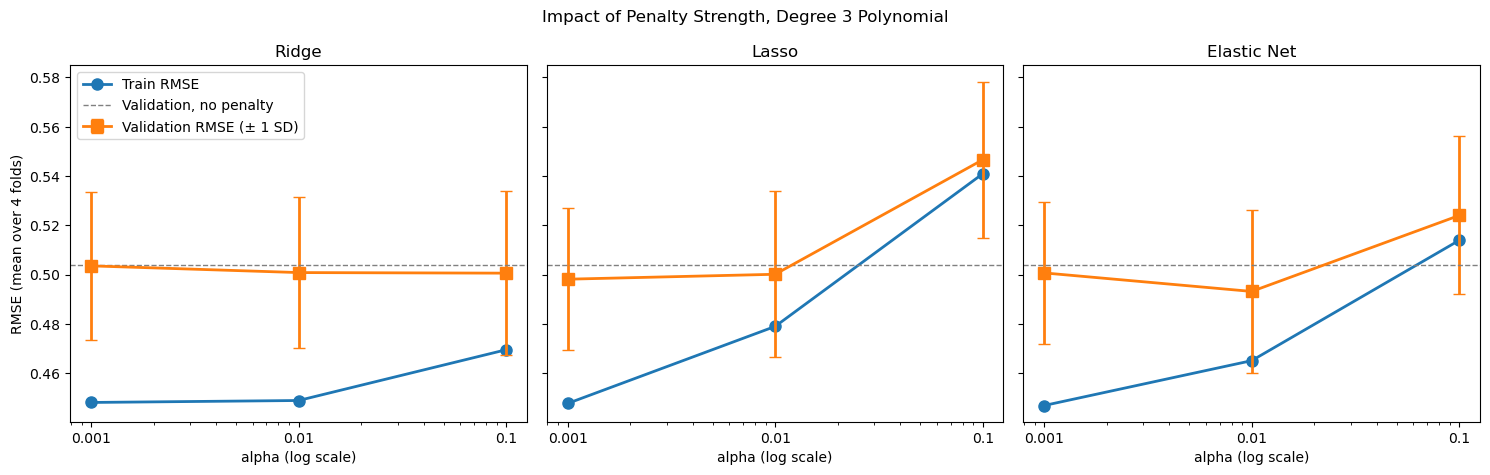

In [12]:
reg_table = pd.DataFrame([r for r in results if r['model'] in regularized_names])
baseline = next(r for r in results if r['model'] == f'SGD (no penalty), degree {POLY_DEGREE}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, (label, penalty) in zip(axes, PENALTIES.items()):
	rows = reg_table[reg_table['penalty'] == penalty]
	ax.plot(rows['alpha'], rows['train RMSE'], marker='o', markersize=8, lw=2, label='Train RMSE')
	ax.errorbar(rows['alpha'], rows['val RMSE'], yerr=rows['val RMSE std'], marker='s', markersize=8, lw=2, capsize=4, label='Validation RMSE (± 1 SD)')
	ax.axhline(baseline['val RMSE'], color='gray', ls='--', lw=1, label='Validation, no penalty')
	ax.set_xscale('log')
	ax.set_xticks(ALPHAS, labels=[str(a) for a in ALPHAS])
	ax.set_xlabel('alpha (log scale)')
	ax.set_title(label)
axes[0].set_ylabel('RMSE (mean over 4 folds)')
axes[0].legend(loc='upper left')
fig.suptitle(f'Impact of Penalty Strength, Degree {POLY_DEGREE} Polynomial')
plt.tight_layout()
plt.show()

A degree 3 model has 164 weights, too many for a full coefficient table, so each model is summarized by how many weights it keeps and how large they are (fit on the full training set):

In [13]:
def weight_summary(name):
	"""Fit a model on the full training set and summarize its weights."""
	fitted = clone(models[name]).fit(X, y)
	weights = pd.Series(fitted['model'].coef_, index=poly_term_names(fitted))
	return {
		'# weights': len(weights),
		'# weights = 0': int((weights == 0).sum()),
		'sum of |weights|': weights.abs().sum(),
		'largest |weight|': weights.abs().max(),
		'largest weight is on': weights.abs().idxmax(),
	}


pd.DataFrame({name: weight_summary(name) for name in [f'SGD (no penalty), degree {POLY_DEGREE}', *regularized_names]}).T.round(3)

,# weights,# weights = 0,sum of |weights|,largest |weight|,largest weight is on
"SGD (no penalty), degree 3",164,0,19.652826,0.663249,GDP x LifeExp^2
"Ridge (alpha=0.001), degree 3",164,0,18.44572,0.616147,GDP x LifeExp^2
"Ridge (alpha=0.01), degree 3",164,0,11.474997,0.430029,GDP
"Ridge (alpha=0.1), degree 3",164,0,4.467133,0.269151,GDP
"Lasso (alpha=0.001), degree 3",164,29,14.073988,0.606142,GDP x LifeExp^2
"Lasso (alpha=0.01), degree 3",164,122,3.098497,0.413602,LifeExp
"Lasso (alpha=0.1), degree 3",164,156,1.079951,0.333745,GDP
"Elastic Net (alpha=0.001), degree 3",164,13,16.153109,0.611316,GDP x LifeExp^2
"Elastic Net (alpha=0.01), degree 3",164,92,4.538487,0.40436,LifeExp
"Elastic Net (alpha=0.1), degree 3",164,150,1.269166,0.320062,GDP


#### Notes / Observations

**Impact of the penalty strength** (degree 3, 164 weights)
- **Unlike Appendix B, regularization now helps.** The best penalty (Elastic Net, alpha = 0.01) cuts validation RMSE from 0.504 to 0.493 and halves the train / validation gap (0.056 to 0.028). The linear model had no overfitting to remove; this one does.
- **Ridge:** gains are small (0.504 to 0.501), but the gap closes as alpha rises (0.055, 0.052, 0.031) and the total weight size drops from 19.7 to 4.5. Ridge shrinks all 164 weights evenly and never removes any, so the many noisy cubic terms stay in the model, just smaller.
- **Lasso:** best at the weakest setting (0.498 at alpha = 0.001, dropping 29 terms). At 0.01 it keeps only 42 of 164 terms (0.500), and at 0.1 only 8, which underfits (0.547, *worse than the linear model's 0.534*).
- **Elastic Net:** a clear U shape: 0.501 at 0.001, **0.493 at 0.01**, 0.524 at 0.1. At 0.01 it removes 92 terms (keeping 72) while still shrinking the rest, getting both the cleanup of Lasso and the stability of Ridge.
- **Every penalty follows the same pattern as alpha grows:** train RMSE rises steadily while validation first falls or holds, then rises. Too little penalty overfits (big gap), too much underfits (both high).

**What the penalty removes**
- With no or weak penalty, the single largest weight (0.66) is on **GDP x LifeExp²**, a cubic term built from the two most correlated features (r = 0.85). Large weights on such terms usually mean the model is fitting quirks of the training rows: GDP, LifeExp and their products carry nearly the same information, so the fit can trade large positive and negative weights between them.
- From alpha = 0.01 up, the largest weight moves back to a plain feature (GDP or LifeExp), which matches what the data analysis found to matter most.

**A note on the size of the gains:** the fold to fold standard deviation is about 0.03, larger than the differences between most penalties here. The steady narrowing of the gap is the clearer signal that the penalty is doing its job.

# QE.3 Other Hyperparameters

## Learning Rate Schedule and Initial Learning Rate (`eta0`)

Same four schedules and four `eta0` values as QD.4, using the best penalty and alpha from QE.2. Polynomial features have heavier tails than the originals (a few rows have very large squared or cubed values), so the learning rate should matter more here than it did for the linear model.

In [14]:
best_reg = min((r for r in results if r['model'] in regularized_names), key=lambda r: r['val RMSE'])
best_penalty, best_alpha = best_reg['penalty'], best_reg['alpha']
best_l1_ratio = 0.5 if best_penalty == 'elasticnet' else np.nan
print(f"Best from QE.2: {best_reg['model']}  (val RMSE {best_reg['val RMSE']:.4f})")

Best from QE.2: Elastic Net (alpha=0.01), degree 3  (val RMSE 0.4931)


In [15]:
LEARNING_RATES = ['constant', 'invscaling', 'adaptive', 'optimal']
ETA0S = [0.0001, 0.001, 0.01, 0.1]

lr_names = []
for learning_rate in LEARNING_RATES:
	for eta0 in ETA0S:
		name = f'{best_penalty} alpha={best_alpha}, {learning_rate} eta0={eta0}, degree {POLY_DEGREE}'
		evaluate(name, SGDRegressor(penalty=best_penalty, alpha=best_alpha, l1_ratio=0.5, learning_rate=learning_rate, eta0=eta0, random_state=SEED), POLY_DEGREE,
				 method='SGD', penalty=best_penalty, alpha=best_alpha, l1_ratio=best_l1_ratio, learning_rate=learning_rate, eta0=eta0)
		lr_names.append(name)

lr_table = pd.DataFrame([r for r in results if r['model'] in lr_names])
show_diverged(lr_table, columns=['val RMSE']).pivot(index='learning_rate', columns='eta0', values='val RMSE').loc[LEARNING_RATES]

eta0,0.0001,0.0010,0.0100,0.1000
learning_rate,,,,
constant,0.5015,0.4992,diverged,diverged
invscaling,0.6855,0.504,0.4931,diverged
adaptive,0.5004,0.4928,diverged,diverged
optimal,diverged,diverged,diverged,diverged


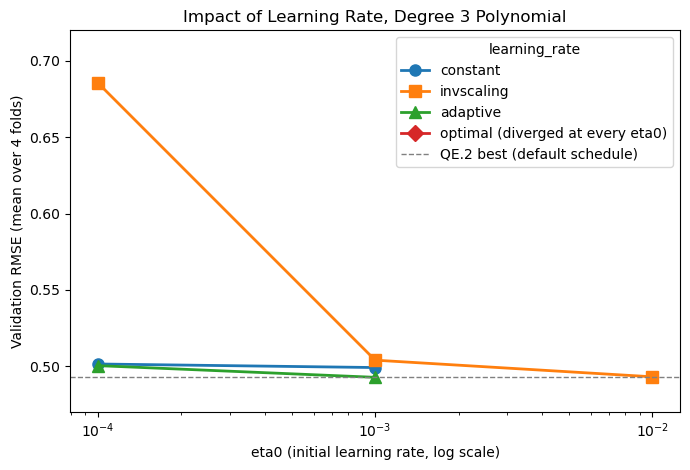

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.8))
for learning_rate, marker in zip(LEARNING_RATES, ['o', 's', '^', 'D']):
	rows = lr_table[(lr_table['learning_rate'] == learning_rate) & (lr_table['val RMSE'] <= DIVERGED)]
	ax.plot(rows['eta0'], rows['val RMSE'], marker=marker, markersize=8, lw=2, label=learning_rate if len(rows) else f'{learning_rate} (diverged at every eta0)')
ax.axhline(best_reg['val RMSE'], color='gray', ls='--', lw=1, label='QE.2 best (default schedule)')
ax.set_xscale('log')
ax.set_ylim(0.47, 0.72)  # diverged runs are left off the chart
ax.set_xlabel('eta0 (initial learning rate, log scale)')
ax.set_ylabel('Validation RMSE (mean over 4 folds)')
ax.set_title(f'Impact of Learning Rate, Degree {POLY_DEGREE} Polynomial')
ax.legend(title='learning_rate')
plt.tight_layout()
plt.show()

#### Notes / Observations
- **The safe range of learning rates shrinks a lot with polynomial features.** In Appendix B every schedule worked up to `eta0 = 0.1`. Here `constant` and `adaptive` already diverge at `eta0 = 0.01`, and everything diverges at `0.1`. The reason is the large rows described in QE.1: the same step size produces much bigger updates.
- **`invscaling` survives `eta0 = 0.01`** because its step shrinks fast: after the first epoch (about 1,170 updates) it is already down to about 0.0017.
- **Too small is slow:** `invscaling` with `eta0 = 0.0001` starts small and keeps shrinking, so it never reaches the minimum (0.686).
- **`optimal` diverges at every `eta0`.** It ignores `eta0` and sets its step from alpha, which at alpha = 0.01 starts far too large for these features. (With alpha = 0.001 in Appendix B it at least ran.)
- **Best: `adaptive` with `eta0 = 0.001`** (0.4928). It takes full-size steps until the training loss stalls, then cuts the step by 5x, so it moves quickly early and settles precisely at the end. It edges out the default `invscaling` with `eta0 = 0.01` (0.4931), but the difference is tiny compared with the fold to fold spread (0.033).

## Elastic Net Mixing (`l1_ratio`)

Same idea as QD.4: slide Elastic Net between Ridge (`0`) and Lasso (`1`), here at the best alpha from QE.2 with default learning rate settings.

In [17]:
L1_RATIOS = [0.15, 0.5, 0.85]

l1_names = []
for l1_ratio in L1_RATIOS:
	name = f'Elastic Net (alpha={best_alpha}, l1_ratio={l1_ratio}), degree {POLY_DEGREE}'
	evaluate(name, SGDRegressor(penalty='elasticnet', alpha=best_alpha, l1_ratio=l1_ratio, random_state=SEED), POLY_DEGREE,
			 method='SGD', penalty='elasticnet', alpha=best_alpha, l1_ratio=l1_ratio)
	l1_names.append(name)

mixing_names = [f'Ridge (alpha={best_alpha}), degree {POLY_DEGREE}', *l1_names, f'Lasso (alpha={best_alpha}), degree {POLY_DEGREE}']
zero_weights = {name: weight_summary(name)['# weights = 0'] for name in mixing_names}

results_table(mixing_names).assign(**{'# weights = 0': lambda d: d.index.map(zero_weights)})

,degree,method,penalty,alpha,l1_ratio,train RMSE,val RMSE,val RMSE std,gap,val MAE,val R2,# weights = 0
model,,,,,,,,,,,,
"Ridge (alpha=0.01), degree 3",3,SGD,l2,0.01,NaN,0.4489,0.5008,0.0305,0.0519,0.3850,0.7955,0
"Elastic Net (alpha=0.01, l1_ratio=0.15), degree 3",3,SGD,elasticnet,0.01,0.15,0.4505,0.4945,0.0300,0.0440,0.3814,0.8006,46
"Elastic Net (alpha=0.01, l1_ratio=0.5), degree 3",3,SGD,elasticnet,0.01,0.50,0.4650,0.4931,0.0329,0.0281,0.3814,0.8017,92
"Elastic Net (alpha=0.01, l1_ratio=0.85), degree 3",3,SGD,elasticnet,0.01,0.85,0.4750,0.4975,0.0338,0.0225,0.3835,0.7981,114
"Lasso (alpha=0.01), degree 3",3,SGD,l1,0.01,NaN,0.4789,0.5001,0.0337,0.0212,0.3852,0.7960,122


#### Notes / Observations
- **The best mix is in the middle.** At alpha = 0.01, validation RMSE goes Ridge 0.501, `l1_ratio = 0.15` 0.4945, **0.5 0.4931**, 0.85 0.4975, Lasso 0.500.
- The more L1 in the mix, the more terms are set to 0 (0, 46, 92, 114, 122 of 164) and the smaller the train / validation gap (0.052 down to 0.021).
- This differs from Appendix B, where less L1 was always better. With 164 terms, many of them redundant products of the same correlated features, some L1 helps by **removing** noisy terms outright. Too much L1 starts removing useful ones and the model underfits.

## Polynomial Degree with Regularization

QE.1 compared degrees without any penalty. Here degrees 2, 3 and 4 are retried with the best penalty, alpha and schedule found so far, across three learning rates, to see whether regularization lets a higher degree pay off.

In [18]:
best_lr = min((r for r in results if r['model'] in lr_names), key=lambda r: r['val RMSE'])
best_learning_rate = best_lr['learning_rate']
print(f"Best schedule from the learning rate search: {best_learning_rate} (eta0={best_lr['eta0']}, val RMSE {best_lr['val RMSE']:.4f})")

DEGREE_ETA0S = [0.0001, 0.001, 0.01]

poly_names = []
for degree in [2, 3, 4]:
	for eta0 in DEGREE_ETA0S:
		name = f'{best_penalty} alpha={best_alpha}, {best_learning_rate} eta0={eta0}, degree {degree}'
		if name not in models:  # degree 3 runs already exist from the learning rate search
			evaluate(name, SGDRegressor(penalty=best_penalty, alpha=best_alpha, l1_ratio=0.5, learning_rate=best_learning_rate, eta0=eta0, random_state=SEED), degree,
					 method='SGD', penalty=best_penalty, alpha=best_alpha, l1_ratio=best_l1_ratio, learning_rate=best_learning_rate, eta0=eta0)
		poly_names.append(name)

poly_table = pd.DataFrame([r for r in results if r['model'] in poly_names])
show_diverged(poly_table, columns=['val RMSE']).pivot(index='degree', columns='eta0', values='val RMSE')

Best schedule from the learning rate search: adaptive (eta0=0.001, val RMSE 0.4928)


eta0,0.0001,0.0010,0.0100
degree,,,
2,0.5147,0.5117,0.512
3,0.5004,0.4928,diverged
4,0.4951,diverged,diverged


In [19]:
show_diverged(poly_table, columns=['train RMSE', 'gap']).pivot(index='degree', columns='eta0', values=['train RMSE', 'gap'])

train RMSE                         gap                    
eta0       0.0001    0.0010    0.0100  0.0001    0.0010    0.0100
degree                                                           
2          0.5029     0.498    0.4974  0.0118    0.0138    0.0145
3          0.4743    0.4614  diverged  0.0261    0.0314  diverged
4          0.4478  diverged  diverged  0.0473  diverged  diverged

#### Notes / Observations
- **Degree 2 barely needs the penalty.** Its gap stays small (0.012 to 0.015) and validation RMSE (0.512) is about the same as unpenalized SGD (0.512). There is little overfitting to fix, and too little flexibility to match degree 3.
- **Degree 3 is the best fit** (0.4928 at `eta0 = 0.001`), with a gap of 0.031.
- **Regularization rescues degree 4,** from a closed-form validation RMSE of 0.848 (and SGD divergence with defaults) to **0.495**, close to degree 3. It only trains with `eta0 = 0.0001`, because of its very large rows.
- Degree 4 still does not beat degree 3, and its gap is larger (0.047 vs 0.031): it has 494 weights, more noise to fit, and no gain to show for it. Degree 3 is the sweet spot between the two.

# QE.4 Select the Best Regularized Model

Every regularized SGD model trained above (QE.2 and QE.3, any degree) is a candidate. The winner is the one with the lowest mean validation RMSE.

In [20]:
candidates = pd.DataFrame([r for r in results if r['model'] in regularized_names + lr_names + l1_names + poly_names]).drop_duplicates('config').set_index('model').drop(columns='config')
candidates = candidates[candidates['val RMSE'] <= DIVERGED].sort_values('val RMSE')

best_name = candidates.index[0]
best_degree = int(candidates.loc[best_name, 'degree'])
best_params = models[best_name]['model'].get_params()
print(f'Selected: {best_name}')
print({'degree': best_degree, **{k: best_params[k] for k in ['penalty', 'alpha', 'l1_ratio', 'learning_rate', 'eta0', 'power_t', 'max_iter', 'tol', 'random_state']}})

candidates.drop(columns='method').head(10).round(4)

Selected: elasticnet alpha=0.01, adaptive eta0=0.001, degree 3
{'degree': 3, 'penalty': 'elasticnet', 'alpha': 0.01, 'l1_ratio': 0.5, 'learning_rate': 'adaptive', 'eta0': 0.001, 'power_t': 0.25, 'max_iter': 1000, 'tol': 0.001, 'random_state': 42}


,degree,penalty,alpha,l1_ratio,train RMSE,val RMSE,val RMSE std,gap,val MAE,val R2,learning_rate,eta0
model,,,,,,,,,,,,
"elasticnet alpha=0.01, adaptive eta0=0.001, degree 3",3,elasticnet,0.010,0.50,0.4614,0.4928,0.0332,0.0314,0.3805,0.8019,adaptive,0.0010
"Elastic Net (alpha=0.01), degree 3",3,elasticnet,0.010,0.50,0.4650,0.4931,0.0329,0.0281,0.3814,0.8017,NaN,NaN
"Elastic Net (alpha=0.01, l1_ratio=0.15), degree 3",3,elasticnet,0.010,0.15,0.4505,0.4945,0.0300,0.0440,0.3814,0.8006,NaN,NaN
"elasticnet alpha=0.01, adaptive eta0=0.0001, degree 4",4,elasticnet,0.010,0.50,0.4478,0.4951,0.0287,0.0473,0.3812,0.8004,adaptive,0.0001
"Elastic Net (alpha=0.01, l1_ratio=0.85), degree 3",3,elasticnet,0.010,0.85,0.4750,0.4975,0.0338,0.0225,0.3835,0.7981,NaN,NaN
"Lasso (alpha=0.001), degree 3",3,l1,0.001,NaN,0.4476,0.4981,0.0287,0.0505,0.3844,0.7978,NaN,NaN
"elasticnet alpha=0.01, constant eta0=0.001, degree 3",3,elasticnet,0.010,0.50,0.4691,0.4992,0.0362,0.0301,0.3856,0.7965,constant,0.0010
"Lasso (alpha=0.01), degree 3",3,l1,0.010,NaN,0.4789,0.5001,0.0337,0.0212,0.3852,0.7960,NaN,NaN
"elasticnet alpha=0.01, adaptive eta0=0.0001, degree 3",3,elasticnet,0.010,0.50,0.4743,0.5004,0.0319,0.0261,0.3866,0.7958,adaptive,0.0001


#### Notes / Observations
- **Selected: degree 3 polynomial, Elastic Net (`alpha = 0.01`, `l1_ratio = 0.5`), `learning_rate = 'adaptive'`, `eta0 = 0.001`.** Validation RMSE **0.4928 ± 0.0332**, R² 0.802, MAE 0.381. Train RMSE 0.461, so the gap is 0.031.
- Compared with the selected linear model in Appendix B (0.5342), that is **7.8% lower validation RMSE** and R² up from 0.77 to 0.80.
- **The top of the table is close.** The same Elastic Net with the default `invscaling` schedule (0.4931), `l1_ratio = 0.15` (0.4945) and the regularized degree 4 model (0.4951) are all within 0.0025 of the winner, about 1/13 of the fold to fold spread. What clearly matters is **degree 3 with a moderate Elastic Net penalty and a stable learning rate**; the exact schedule is a minor detail.

# QE.5 Training and Validation Loss by Epoch (Selected Model)

Same approach as QD.6: rebuild the selected SGD with `max_iter=1` and `warm_start=True`, call `fit` once per epoch, and record Train and Validation RMSE after each call. This runs on each of the 4 CV folds and the curves are averaged. `tol=None` turns off early stopping so every run goes the full 100 epochs.

> **One adjustment for the `adaptive` schedule.** In a normal `fit`, `adaptive` divides the learning rate by 5 every time the training loss fails to improve by `tol` for 5 epochs in a row. With `max_iter=1`, each `fit` call only sees one epoch, so it can never count 5 stalled epochs and the step stays stuck at `eta0` forever. To make the curve match the selected model, the loop applies the same rule itself between calls (tracking the training loss and lowering `eta0` with `set_params`). The plain loop without this adjustment is shown afterwards for comparison.

In [21]:
N_EPOCHS = 100


def rmse(y_true, y_pred):
	return np.sqrt(mean_squared_error(y_true, y_pred))


def epoch_curves(name, n_epochs, apply_adaptive_rule=True):
	"""Average Train / Validation RMSE per epoch over the 4 CV folds, training one epoch per fit call.

	With apply_adaptive_rule, an 'adaptive' learning rate is divided by 5 after 5 epochs without
	a tol sized improvement in training loss, the same rule a single long fit would apply.
	"""
	degree = int(models[name]['poly'].degree)
	train_curves, val_curves, eta_curves = [], [], []
	for train_idx, val_idx in cv.split(X):
		features = make_pipeline_for('passthrough', degree)[:-1].fit(X.iloc[train_idx])  # every step except the model
		X_tr, X_val = features.transform(X.iloc[train_idx]), features.transform(X.iloc[val_idx])
		y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

		template = models[name]['model']
		sgd = clone(template).set_params(max_iter=1, warm_start=True, tol=None)
		adaptive = apply_adaptive_rule and template.learning_rate == 'adaptive'
		best_loss, stalled_epochs = np.inf, 0

		train_rmse, val_rmse, etas = [], [], []
		for epoch in range(n_epochs):
			with warnings.catch_warnings():
				warnings.simplefilter('ignore')  # ConvergenceWarning: expected, since max_iter=1
				sgd.fit(X_tr, y_tr)
			train_rmse.append(rmse(y_tr, sgd.predict(X_tr)))
			val_rmse.append(rmse(y_val, sgd.predict(X_val)))
			etas.append(sgd.eta0)

			if adaptive:
				loss = 0.5 * len(y_tr) * train_rmse[-1] ** 2  # SGDRegressor's summed squared loss
				stalled_epochs = stalled_epochs + 1 if loss > best_loss - template.tol * len(y_tr) else 0
				best_loss = min(best_loss, loss)
				if stalled_epochs >= template.n_iter_no_change and sgd.eta0 > 1e-6:
					sgd.set_params(eta0=sgd.eta0 / 5)
					stalled_epochs = 0
		train_curves.append(train_rmse)
		val_curves.append(val_rmse)
		eta_curves.append(etas)

	train_curves, val_curves = np.array(train_curves), np.array(val_curves)
	return pd.DataFrame({
		'epoch': np.arange(1, n_epochs + 1),
		'train RMSE': train_curves.mean(axis=0),
		'val RMSE': val_curves.mean(axis=0),
		'val RMSE std': val_curves.std(axis=0),
		'learning rate (fold 1)': eta_curves[0],
	}).set_index('epoch')


epoch_df = epoch_curves(best_name, N_EPOCHS)
epoch_df.loc[[1, 2, 3, 5, 10, 15, 20, 30, 50, 100]].assign(**{'learning rate (fold 1)': lambda d: d['learning rate (fold 1)'].map('{:.1e}'.format)}).round(4)

,train RMSE,val RMSE,val RMSE std,learning rate (fold 1)
epoch,,,,
1,1.8061,1.8220,0.1141,1.0e-03
2,0.7342,0.7635,0.0792,1.0e-03
3,0.5212,0.5522,0.0439,1.0e-03
5,0.4824,0.5132,0.0290,1.0e-03
10,0.4738,0.5069,0.0286,1.0e-03
15,0.4626,0.4956,0.0326,2.0e-04
20,0.4610,0.4937,0.0332,4.0e-05
30,0.4608,0.4936,0.0333,1.6e-06
50,0.4608,0.4936,0.0334,3.2e-07


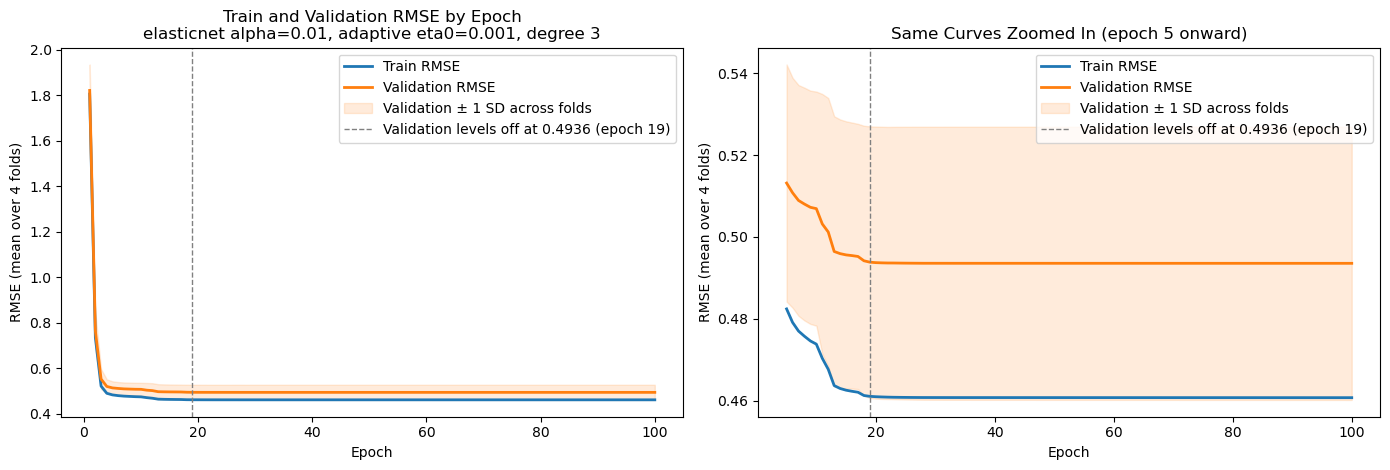

In [22]:
def plot_epoch_curves(epoch_df, title, ax, start_epoch=1):
	"""Plot mean Train and Validation RMSE by epoch, with a band for the fold to fold spread and the lowest validation point marked."""
	df = epoch_df.loc[start_epoch:]
	ax.plot(df.index, df['train RMSE'], lw=2, label='Train RMSE')
	ax.plot(df.index, df['val RMSE'], lw=2, label='Validation RMSE')
	ax.fill_between(df.index, df['val RMSE'] - df['val RMSE std'], df['val RMSE'] + df['val RMSE std'],
					color='tab:orange', alpha=0.15, label='Validation ± 1 SD across folds')
	lowest = df['val RMSE'].min()
	if df['val RMSE'].iloc[-1] - lowest < 0.0005:  # flat at the end: mark where it levels off, not a meaningless last epoch
		settled = (df['val RMSE'] <= lowest + 0.0005).idxmax()
		ax.axvline(settled, color='gray', ls='--', lw=1, label=f'Validation levels off at {lowest:.4f} (epoch {settled})')
	else:
		ax.axvline(df['val RMSE'].idxmin(), color='gray', ls='--', lw=1, label=f"Lowest validation RMSE {lowest:.4f} (epoch {df['val RMSE'].idxmin()})")
	ax.set_xlabel('Epoch')
	ax.set_ylabel('RMSE (mean over 4 folds)')
	ax.set_title(title)
	ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_epoch_curves(epoch_df, f'Train and Validation RMSE by Epoch\n{best_name}', axes[0])
plot_epoch_curves(epoch_df, 'Same Curves Zoomed In (epoch 5 onward)', axes[1], start_epoch=5)
plt.tight_layout()
plt.show()

For comparison, the plain loop from the hint (no adaptive rule, so the learning rate stays at `eta0` every epoch):

In [23]:
plain_epoch_df = epoch_curves(best_name, N_EPOCHS, apply_adaptive_rule=False)

pd.DataFrame({
	f'Loop with adaptive rule, epoch {N_EPOCHS}': epoch_df.loc[N_EPOCHS, ['train RMSE', 'val RMSE']],
	f'Plain loop (eta0 fixed), epoch {N_EPOCHS}': plain_epoch_df.loc[N_EPOCHS, ['train RMSE', 'val RMSE']],
	'Regular fit with stopping rule (QE.4)': candidates.loc[best_name, ['train RMSE', 'val RMSE']],
}).T.round(4)

,train RMSE,val RMSE
"Loop with adaptive rule, epoch 100",0.460753,0.493564
"Plain loop (eta0 fixed), epoch 100",0.468537,0.504976
Regular fit with stopping rule (QE.4),0.461358,0.49278


#### Notes / Observations
- **Fast start:** validation RMSE drops from 1.82 after epoch 1 to 0.552 by epoch 3 and 0.507 by epoch 10, all at the starting step of 0.001.
- **Each step cut shows up as a drop in the curves.** Around epochs 11 to 15 the training loss stops improving, so the step is divided by 5 (to 0.0002 in fold 1), and validation RMSE falls from 0.507 to 0.496. Further cuts follow quickly, and by **epoch 20 both curves are flat** (train 0.461, validation 0.4937). Smaller steps let the weights settle into the minimum instead of bouncing around it.
- **No overfitting with training time.** The validation curve never turns back up, even after 100 epochs, and the gap stays steady at about 0.033. The Elastic Net penalty caps how far the weights can chase noise, so training longer is safe. Compare this with the unpenalized curves in QE.7, where validation RMSE rises again.
- **Why the adaptive rule matters:** the plain loop from the hint keeps the step stuck at 0.001 and plateaus at validation RMSE 0.505, noticeably worse than the model actually selected (0.493). With the rule applied, the loop ends at 0.4936, within 0.001 of the regular `fit`, so these curves are a faithful picture of the selected model.

# QE.6 Train the Selected Model on the Entire Training Set

The selected pipeline is refit on all 1,559 training rows with its default stopping rule. The test set is still untouched.

In [24]:
final_model = clone(models[best_name]).fit(X, y)
final_sgd = final_model['model']

print(f'Final model: {best_name}')
print(f'Features after polynomial expansion: {final_sgd.n_features_in_}')
print(f'Epochs run: {final_sgd.n_iter_}')
print(f'Training RMSE (entire training set): {rmse(y, final_model.predict(X)):.4f}')
print(f"Expected RMSE on unseen data (4-fold CV): {candidates.loc[best_name, 'val RMSE']:.4f} ± {candidates.loc[best_name, 'val RMSE std']:.4f}")

Final model: elasticnet alpha=0.01, adaptive eta0=0.001, degree 3
Features after polynomial expansion: 164
Epochs run: 39
Training RMSE (entire training set): 0.4657
Expected RMSE on unseen data (4-fold CV): 0.4928 ± 0.0332


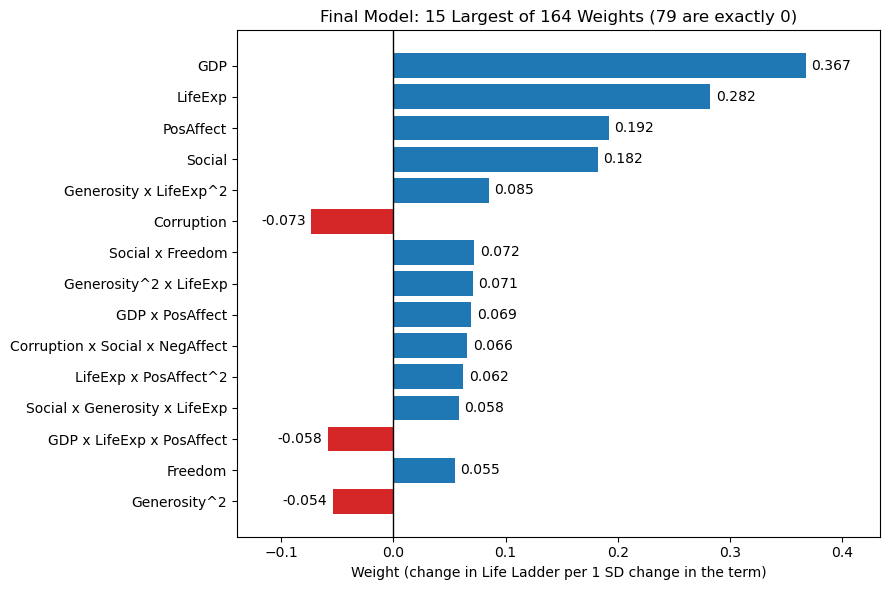

In [25]:
final_weights = pd.Series(final_sgd.coef_, index=poly_term_names(final_model), name='weight')
top_weights = final_weights[final_weights.abs().sort_values(ascending=False).index[:15]].sort_values(key=abs)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_weights.index, top_weights, color=['tab:blue' if w > 0 else 'tab:red' for w in top_weights])
for i, w in enumerate(top_weights):
	ax.text(w + (0.005 if w >= 0 else -0.005), i, f'{w:.3f}', va='center', ha='left' if w >= 0 else 'right')
ax.axvline(0, color='black', lw=1)
ax.margins(x=0.15)  # room for the value labels
ax.set_xlabel(f'Weight (change in {TARGET} per 1 SD change in the term)')
ax.set_title(f'Final Model: 15 Largest of {len(final_weights)} Weights ({int((final_weights == 0).sum())} are exactly 0)')
plt.tight_layout()
plt.show()

#### Notes / Observations
- The final model trains in **39 epochs** on all 1,559 training rows, with **training RMSE 0.466**. Its expected error on new data, from cross-validation, is **0.493 ± 0.033** Life Ladder points (R² about 0.80).
- **The Elastic Net penalty removed 79 of the 164 terms**, leaving 85.
- **Plain features still carry the most weight:** GDP (0.37), LifeExp (0.28), PosAffect (0.19) and Social (0.18) are the top four, the same four as the linear model. Corruption keeps its negative sign (-0.07).
- **The remaining terms are small corrections** (all below 0.09), mostly products of features: ex: Social x Freedom (0.07) and GDP x PosAffect (0.07). Together they are what lowers the error by 7.8% over the linear model.
- Individual polynomial weights should not be read as stand-alone effects: GDP, LifeExp and their products overlap heavily, so the weight on any one term depends on which related terms survived the penalty. Compared with the linear model, some of Social support's weight (0.28 to 0.18) has moved onto its interaction terms.
- `final_model` is a full pipeline (impute, transform, expand, scale, predict), so it can be applied directly to the raw test set. It is saved below as `MODELS/polynomial_regression_model.joblib` for QF.

## Save the Final Model for QF

The fitted pipeline is written to disk so the main notebook (QF) can load it and predict on the test set without retraining. The file also records the model name and its cross-validation scores, so QF can compare the test RMSE against what cross-validation expected. Nothing in this appendix reads the test set.

In [26]:
import os
import joblib

model_path = '/Q1_OLD/MODELS/polynomial_regression_model.joblib'
os.makedirs(os.path.dirname(model_path), exist_ok=True)

joblib.dump({
	'name': best_name,
	'model': final_model,
	'train RMSE': rmse(y, final_model.predict(X)),
	'val RMSE': candidates.loc[best_name, 'val RMSE'],
	'val RMSE std': candidates.loc[best_name, 'val RMSE std'],
	'source': 'Appendix C, QE.6',
}, model_path)

print(f'Saved {best_name} to {model_path}')

Saved elasticnet alpha=0.01, adaptive eta0=0.001, degree 3 to /Users/mrt/Documents/MrT/IUBloomington/Fall 2026 - Applied Machine Learning/code/hw/Applied-ML-HW1/Q1/MODELS/polynomial_regression_model.joblib


# QE.7 Does the Model Overfit or Underfit?

QE.1 already compared train and validation RMSE across degrees. Three more views of the validation loss complete the picture:
1. **Penalty strength:** a wider sweep of alpha at the selected degree and schedule.
2. **Epochs:** how the validation loss moves over training time *without* a penalty, compared with the selected model in QE.5.
3. **Training set size (learning curves):** how train and validation RMSE change as the model sees more rows.

## Validation Loss vs Penalty Strength

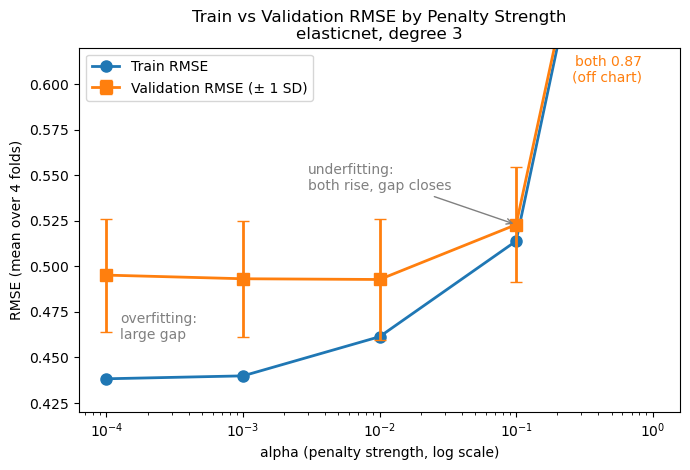

,alpha,train RMSE,val RMSE,val RMSE std,gap
model,,,,,
"elasticnet alpha=0.0001, adaptive eta0=0.001, degree 3",0.0001,0.4383,0.4952,0.0310,0.0569
"elasticnet alpha=0.001, adaptive eta0=0.001, degree 3",0.0010,0.4399,0.4932,0.0317,0.0533
"elasticnet alpha=0.01, adaptive eta0=0.001, degree 3",0.0100,0.4614,0.4928,0.0332,0.0314
"elasticnet alpha=0.1, adaptive eta0=0.001, degree 3",0.1000,0.5139,0.5229,0.0317,0.0090
"elasticnet alpha=1.0, adaptive eta0=0.001, degree 3",1.0000,0.8671,0.8698,0.0179,0.0028


In [27]:
ALPHA_SWEEP = [0.0001, 0.001, 0.01, 0.1, 1.0]

sweep_names = []
for alpha in ALPHA_SWEEP:
	name = f'{best_penalty} alpha={alpha}, {best_params["learning_rate"]} eta0={best_params["eta0"]}, degree {best_degree}'
	if name not in models:  # the selected alpha already ran
		evaluate(name, clone(models[best_name]['model']).set_params(alpha=alpha), best_degree,
				 method='SGD', penalty=best_penalty, alpha=alpha, learning_rate=best_params['learning_rate'], eta0=best_params['eta0'])
	sweep_names.append(name)

sweep_table = results_table(sweep_names)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(sweep_table['alpha'], sweep_table['train RMSE'], marker='o', markersize=8, lw=2, label='Train RMSE')
ax.errorbar(sweep_table['alpha'], sweep_table['val RMSE'], yerr=sweep_table['val RMSE std'], marker='s', markersize=8, lw=2, capsize=4, label='Validation RMSE (± 1 SD)')
ax.set_xscale('log')
ax.set_xlabel('alpha (penalty strength, log scale)')
ax.set_ylabel('RMSE (mean over 4 folds)')
ax.set_title(f'Train vs Validation RMSE by Penalty Strength\n{best_penalty}, degree {best_degree}')
ax.set_ylim(0.42, 0.62)
for alpha, val in zip(sweep_table['alpha'], sweep_table['val RMSE']):
	if val > 0.62:  # off the chart: label where it went instead
		ax.annotate(f'both {val:.2f}\n(off chart)', xy=(alpha, 0.62), xytext=(-8, -5), textcoords='offset points', ha='right', va='top', color='tab:orange')
first = sweep_table.iloc[0]
ax.annotate('overfitting:\nlarge gap', xy=(ALPHA_SWEEP[0], (first['train RMSE'] + first['val RMSE']) / 2), xytext=(10, 0), textcoords='offset points', va='center', color='gray')
ax.annotate('underfitting:\nboth rise, gap closes', xy=(0.1, sweep_table.loc[sweep_table['alpha'] == 0.1, 'val RMSE'].iloc[0]), xytext=(-150, 25), textcoords='offset points', color='gray', arrowprops={'arrowstyle': '->', 'color': 'gray'})
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

sweep_table[['alpha', 'train RMSE', 'val RMSE', 'val RMSE std', 'gap']]

## Validation Loss vs Epochs Without a Penalty

The same epoch loop as QE.5, for two unpenalized models: the chosen degree, and degree 4 (which QE.1 showed has more features than it can support). Both use a `constant` learning rate small enough to stay stable (`0.001` for the chosen degree, `0.0001` for degree 4, since its larger features diverge otherwise), so the curves show how fitting behaves over time rather than a learning rate problem.

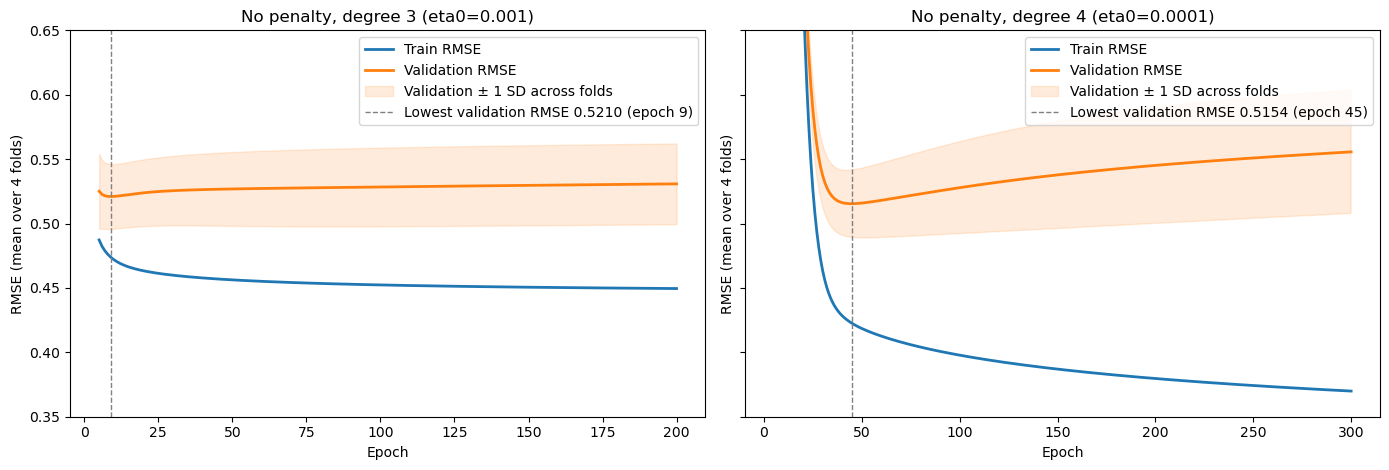

,lowest val RMSE,at epoch,final val RMSE,final train RMSE,final gap
"No penalty, degree 3 (eta0=0.001)",0.5210,9.0,0.5308,0.4495,0.0813
"No penalty, degree 4 (eta0=0.0001)",0.5154,45.0,0.5556,0.3699,0.1857


In [28]:
evaluate(f'SGD (no penalty), constant eta0=0.001, degree {best_degree}', SGDRegressor(penalty=None, learning_rate='constant', eta0=0.001, random_state=SEED), best_degree, method='SGD', penalty='none')
evaluate('SGD (no penalty), constant eta0=0.0001, degree 4', SGDRegressor(penalty=None, learning_rate='constant', eta0=0.0001, random_state=SEED), 4, method='SGD', penalty='none')

unpenalized_curves = {
	f'No penalty, degree {best_degree} (eta0=0.001)': epoch_curves(f'SGD (no penalty), constant eta0=0.001, degree {best_degree}', 200),
	'No penalty, degree 4 (eta0=0.0001)': epoch_curves('SGD (no penalty), constant eta0=0.0001, degree 4', 300),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (title, curves) in zip(axes, unpenalized_curves.items()):
	plot_epoch_curves(curves, title, ax, start_epoch=5)
axes[0].set_ylim(0.35, 0.65)
plt.tight_layout()
plt.show()

pd.DataFrame({
	title: {
		'lowest val RMSE': curves['val RMSE'].min(),
		'at epoch': curves['val RMSE'].idxmin(),
		'final val RMSE': curves['val RMSE'].iloc[-1],
		'final train RMSE': curves['train RMSE'].iloc[-1],
		'final gap': curves['val RMSE'].iloc[-1] - curves['train RMSE'].iloc[-1],
	} for title, curves in unpenalized_curves.items()
}).T.round(4)

## Learning Curves: Validation Loss vs Training Set Size

Each model is trained on growing slices of each training fold (10% to 100%), and scored on that slice (train) and on the full validation fold. Compared side by side:
- the selected **linear** model from Appendix B (Ridge, alpha = 0.001, degree 1),
- the **unpenalized closed form** at the chosen degree (the most flexible fit in QE.1 that did not blow up),
- the **selected polynomial** model from QE.4.

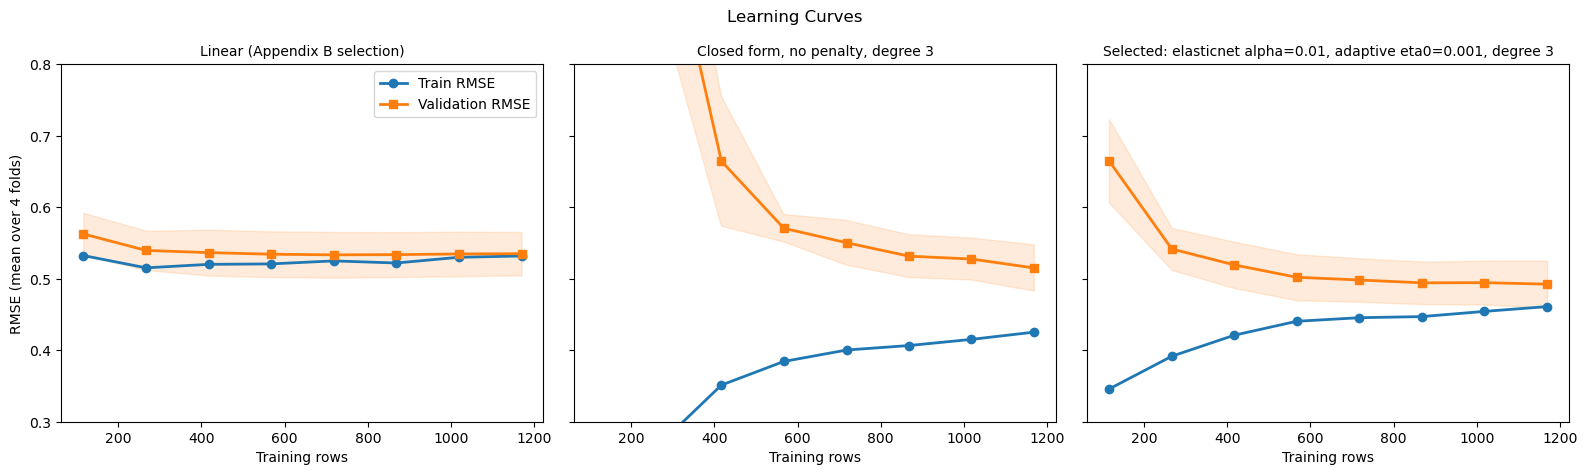

,val RMSE (all rows),gap (all rows),val RMSE (116 rows)
Linear (Appendix B selection),0.5351,0.0032,0.5627
"Closed form, no penalty, degree 3",0.5151,0.0897,2.3962
"Selected: elasticnet alpha=0.01, adaptive eta0=0.001, degree 3",0.4925,0.0314,0.6651


In [29]:
learning_curve_models = {
	'Linear (Appendix B selection)': make_pipeline_for(SGDRegressor(penalty='l2', alpha=0.001, random_state=SEED), 1),
	f'Closed form, no penalty, degree {best_degree}': make_pipeline_for(LinearRegression(), best_degree),
	f'Selected: {best_name}': clone(models[best_name]),
}
train_sizes = np.linspace(0.1, 1.0, 8)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
learning_summary = {}
for ax, (title, pipeline) in zip(axes, learning_curve_models.items()):
	with warnings.catch_warnings():
		warnings.simplefilter('ignore')
		sizes, train_scores, val_scores = learning_curve(pipeline, X, y, cv=cv, train_sizes=train_sizes, scoring='neg_root_mean_squared_error', shuffle=True, random_state=SEED)
	train_rmse, val_rmse = -train_scores.mean(axis=1), -val_scores.mean(axis=1)
	ax.plot(sizes, train_rmse, marker='o', lw=2, label='Train RMSE')
	ax.plot(sizes, val_rmse, marker='s', lw=2, label='Validation RMSE')
	ax.fill_between(sizes, val_rmse - val_scores.std(axis=1), val_rmse + val_scores.std(axis=1), color='tab:orange', alpha=0.15)
	ax.set_xlabel('Training rows')
	ax.set_title(title, fontsize=10)
	learning_summary[title] = {'val RMSE (all rows)': val_rmse[-1], 'gap (all rows)': val_rmse[-1] - train_rmse[-1], f'val RMSE ({sizes[0]} rows)': val_rmse[0]}
axes[0].set_ylim(0.3, 0.8)
axes[0].set_ylabel('RMSE (mean over 4 folds)')
axes[0].legend()
fig.suptitle('Learning Curves')
plt.tight_layout()
plt.show()

pd.DataFrame(learning_summary).T.round(4)

## Polynomial vs Linear, Fold by Fold

Both appendices use the exact same 4 folds, so the selected polynomial model can be compared with the selected linear model on each fold separately. A real improvement should show up on every fold, not just on average.

In [30]:
fold_rmse = {}
for title, pipeline in [('Linear (Appendix B)', learning_curve_models['Linear (Appendix B selection)']), (f'Polynomial (QE.4)', clone(models[best_name]))]:
	with warnings.catch_warnings():
		warnings.simplefilter('ignore')
		fold_rmse[title] = -cross_validate(pipeline, X, y, cv=cv, scoring='neg_root_mean_squared_error')['test_score']

fold_compare = pd.DataFrame(fold_rmse, index=[f'fold {i + 1}' for i in range(4)])
fold_compare['improvement'] = fold_compare.iloc[:, 0] - fold_compare.iloc[:, 1]
fold_compare['improvement %'] = fold_compare['improvement'] / fold_compare.iloc[:, 0] * 100
fold_compare.loc['mean'] = fold_compare.mean()
fold_compare.round(4)

,Linear (Appendix B),Polynomial (QE.4),improvement,improvement %
fold 1,0.5872,0.5498,0.0373,6.3541
fold 2,0.5120,0.4790,0.0331,6.4609
fold 3,0.5217,0.4739,0.0478,9.1596
fold 4,0.5161,0.4684,0.0477,9.2344
mean,0.5342,0.4928,0.0415,7.8023


#### Notes / Observations

**1. Penalty strength** (degree 3, Elastic Net)
- **alpha = 0.0001 and 0.001: overfitting.** Lowest train RMSE (0.438, 0.440) but a large gap (0.057, 0.053) and slightly worse validation (0.495, 0.493).
- **alpha = 0.01: best balance.** Validation 0.4928, gap cut to 0.031.
- **alpha = 0.1: underfitting starts.** The gap is almost gone (0.009) but both errors rise, and validation (0.523) is now worse than the unpenalized degree 2 model (0.512).
- **alpha = 1.0: severe underfitting.** Train and validation are both 0.87, far worse than even the linear model.

**2. Training time without a penalty**
- **Degree 3:** validation RMSE bottoms out at **epoch 9** (0.521), then climbs slowly to 0.531 by epoch 200 while train RMSE keeps falling (to 0.450). The gap grows from about 0.05 to 0.08: the longer it trains, the more it memorizes.
- **Degree 4:** the same pattern, stronger. Validation bottoms out at **epoch 45** (0.515) and climbs to 0.556 by epoch 300, while train falls to 0.370 (gap 0.186).
- **With the penalty (QE.5) the curve stays flat instead.** Regularization is what makes long training safe here. Without it, the epoch count itself would have to be tuned (early stopping).
- (These unpenalized loops keep the step fixed, so their absolute levels sit a bit above a regular `fit`; the rise over time is the point.)

**3. Learning curves** (training set size)
- **Linear: high bias (underfitting).** Train and validation meet at about 0.53 after only about 400 rows and stay there (gap 0.003). More data would not help; the model is simply too simple.
- **Closed form, degree 3, no penalty: high variance (overfitting).** With 116 rows (fewer rows than its 164 features) validation RMSE is 2.40. It falls steadily as rows are added but still has a large gap at full size (train 0.425, validation 0.515), and the validation curve is still sloping down. More data would keep helping.
- **Selected polynomial: a balanced fit.** It reaches the lowest validation RMSE of the three (0.493) with a moderate gap (0.031). The curves are still converging slowly, so some variance remains and more data would help a little, but adding more penalty to close the gap pushes the model into underfitting (part 1).

**4. Fold by fold vs linear**
- **The polynomial model wins on every fold**, by 0.033 to 0.048 RMSE (6.4% to 9.2%). The mean gain (0.042) is about the size of the fold to fold spread, but that spread mostly reflects that fold 1 is harder for *both* models (0.587 linear, 0.550 polynomial). Compared on the same rows, the improvement is consistent.

**Verdict**
| Model | Train RMSE | Val RMSE | Gap | Diagnosis |
|---|---|---|---|---|
| Linear (degree 1) | 0.532 | 0.534 | 0.003 | Underfits: too simple, more data will not help |
| Degree 2, no penalty (SGD) | 0.495 | 0.512 | 0.017 | Slight underfit; small gain over linear |
| Degree 3, no penalty (closed form) | 0.425 | 0.515 | 0.090 | Overfits: extra flexibility goes into noise |
| Degree 4, no penalty (closed form) | 0.297 | 0.848 | 0.550 | Overfits badly |
| **Degree 3 + Elastic Net 0.01 (selected)** | **0.461** | **0.493** | **0.031** | **Best balance**: mild variance remains, but more penalty would underfit |
| Degree 3 + Elastic Net 1.0 | 0.867 | 0.870 | 0.003 | Underfits badly |

**Takeaway:** the linear model in Appendix B was limited by bias, not variance, which is why regularization could not help it. Polynomial features fix the bias (the curved relationships and interactions noted in QB and QC), but bring in variance. A degree 3 polynomial with a moderate Elastic Net penalty balances the two best, lowering validation RMSE by 7.8% on every fold.

# Summary of All Models

In [31]:
summary = pd.DataFrame(results).drop_duplicates('config').set_index('model').sort_values('val RMSE')
show_diverged(summary)

,degree,method,train RMSE,val RMSE,val RMSE std,gap,val MAE,val R2,penalty,alpha,l1_ratio,learning_rate,eta0
model,,,,,,,,,,,,,
"elasticnet alpha=0.01, adaptive eta0=0.001, degree 3",3,SGD,0.4614,0.4928,0.0332,0.0314,0.3805,0.8019,elasticnet,0.0100,0.50,adaptive,0.0010
"Elastic Net (alpha=0.01), degree 3",3,SGD,0.465,0.4931,0.0329,0.0281,0.3814,0.8017,elasticnet,0.0100,0.50,NaN,NaN
"elasticnet alpha=0.001, adaptive eta0=0.001, degree 3",3,SGD,0.4399,0.4932,0.0317,0.0533,0.3806,0.8015,elasticnet,0.0010,NaN,adaptive,0.0010
"Elastic Net (alpha=0.01, l1_ratio=0.15), degree 3",3,SGD,0.4505,0.4945,0.03,0.044,0.3814,0.8006,elasticnet,0.0100,0.15,NaN,NaN
"elasticnet alpha=0.01, adaptive eta0=0.0001, degree 4",4,SGD,0.4478,0.4951,0.0287,0.0473,0.3812,0.8004,elasticnet,0.0100,0.50,adaptive,0.0001
"elasticnet alpha=0.0001, adaptive eta0=0.001, degree 3",3,SGD,0.4383,0.4952,0.031,0.0569,0.3818,0.7999,elasticnet,0.0001,NaN,adaptive,0.0010
"Elastic Net (alpha=0.01, l1_ratio=0.85), degree 3",3,SGD,0.475,0.4975,0.0338,0.0225,0.3835,0.7981,elasticnet,0.0100,0.85,NaN,NaN
"Lasso (alpha=0.001), degree 3",3,SGD,0.4476,0.4981,0.0287,0.0505,0.3844,0.7978,l1,0.0010,NaN,NaN,NaN
"elasticnet alpha=0.01, constant eta0=0.001, degree 3",3,SGD,0.4691,0.4992,0.0362,0.0301,0.3856,0.7965,elasticnet,0.0100,0.50,constant,0.0010
